# House Price Prediction — Step 1: EDA + Feature Engineering

**Goal:** Kaggle ke **Ames Housing** dataset (House Prices: Advanced Regression Techniques competition) par **Linear Regression aur Multiple Linear Regression** se ghar ki keemat (SalePrice) predict karna.

**Is notebook me sirf Step 1 hai:** EDA + Feature Engineering. Model agle step me banega — tum batoge aage kya karna hai.

**Dataset:** `data/train.csv` — 1460 ghar, 79 features + target `SalePrice`. Kaggle se direct download ke liye API token chahiye hota hai, isliye wahi official data OpenML mirror (id 42165) se liya hai — verify kiya: pehle 3 gharon ki keemat Kaggle train.csv se exact match karti hai (208500, 181500, 223500).

**Plan:**
1. EDA — data ko samjho (har step ka "kyun" saath me)
2. Feature Engineering — data ko model-ready banao (har step se pehle kya socha, wo bhi likha hai)
3. Agla step: train/test split → scaling → Linear / Multiple Linear Regression

In [1]:
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

plt.rcParams["figure.dpi"] = 110
df = pd.read_csv("../data/train.csv")
print("Shape (rows, columns):", df.shape)

Shape (rows, columns): (1460, 81)


## 1. Pehli nazar — shape, types, duplicates

**Kyun dekhte hain?** Model banane se pehle ye jaanna zaroori hai: data kitna bada hai, kaunse columns numbers hain aur kaunse categories (text), duplicate rows to nahi hain. Duplicate rows model ko galat seekhate hain — ek hi ghar do baar ginna cheating jaisa hai.

In [2]:
print("Numeric columns:", df.select_dtypes("number").shape[1])
print("Categorical (text) columns:", df.select_dtypes("object").shape[1])
print("Duplicate rows:", df.duplicated().sum())
print("Total missing cells:", int(df.isna().sum().sum()))
df.head(3).T

Numeric columns: 38
Categorical (text) columns: 43
Duplicate rows: 0
Total missing cells: 7829


,0,1,2
Id,1,2,3
MSSubClass,60,20,60
MSZoning,RL,RL,RL
LotFrontage,65.0,80.0,68.0
LotArea,8450,9600,11250
...,...,...,...
MoSold,2,5,9
YrSold,2008,2007,2008
SaleType,WD,WD,WD
SaleCondition,Normal,Normal,Normal


## 2. Target (SalePrice) ko samjho

**Kyun?** Linear Regression ye assume karta hai ki target (ya uske residuals) lagbhag **normal distribution** me hon. Agar target bahut tedha (skewed) hai, to model bade gharon ki keemat hamesha galat batayega. Isliye pehle target ka shape dekho.

**Observation:** SalePrice right-skewed hai (skew = **1.88**) — zyadatar ghar 1–2 lakh ke aas-paas, kuch bahut mehenge. `log1p` lagane ke baad skew **0.12** reh jata hai — lagbhag normal. Isliye modelling ke liye `SalePrice_log = log1p(SalePrice)` use karenge.

count      1460.0
mean     180921.2
std       79442.5
min       34900.0
25%      129975.0
50%      163000.0
75%      214000.0
max      755000.0
Name: SalePrice, dtype: float64
Skew (original): 1.88
Skew (log1p): 0.12


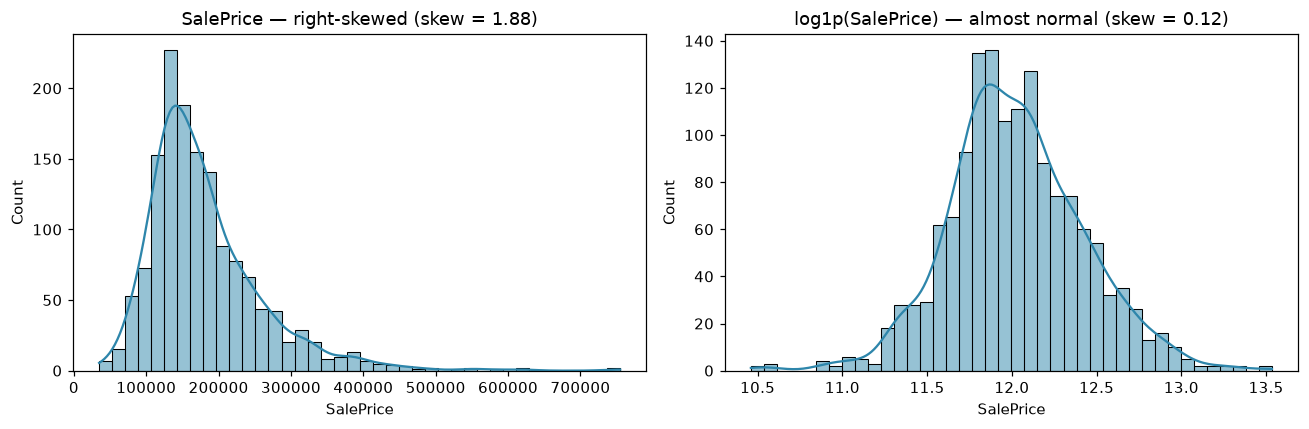

In [3]:
print(df["SalePrice"].describe().round(1))
print("Skew (original):", round(df["SalePrice"].skew(), 2))
print("Skew (log1p):", round(np.log1p(df["SalePrice"]).skew(), 2))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df["SalePrice"], bins=40, kde=True, ax=ax[0], color="#2E86AB")
ax[0].set_title("SalePrice — right-skewed (skew = 1.88)")
sns.histplot(np.log1p(df["SalePrice"]), bins=40, kde=True, ax=ax[1], color="#2E86AB")
ax[1].set_title("log1p(SalePrice) — almost normal (skew = 0.12)")
fig.tight_layout()
fig.savefig("../figures/fig_target_dist.png")
plt.show()

## 3. Missing values — pehle KYUN poochho, phir bharo

**Sabse badi galti jo beginners karte hain:** missing dekhte hi median/mode bhar dena. Pehle ye socho — **ye value missing KYUN hai?**

Is dataset me 3 tarah ki missing values hain:
- **Cheez hai hi nahi:** `PoolQC` 1453/1460 khali hai — kyunki 99.5% gharon me **pool hai hi nahi**. Khali hona yahan ek information hai, kami nahi. Ise median bharna bekaar hota.
- **Ghar ka hissa hi nahi:** `Garage*` 81 khali (garage nahi hai), `Bsmt*` 37–38 khali (basement nahi hai).
- **Asli me missing:** `LotFrontage` 259 khali (17.7%) — ye waise hi record nahi hua. Ise bharna padega.

PoolQC          1453
MiscFeature     1406
Alley           1369
Fence           1179
MasVnrType       872
FireplaceQu      690
LotFrontage      259
GarageType        81
GarageYrBlt       81
GarageFinish      81
GarageQual        81
GarageCond        81
BsmtExposure      38
BsmtFinType2      38
BsmtQual          37
BsmtCond          37
BsmtFinType1      37
MasVnrArea         8
Electrical         1
dtype: int64
Total missing cells: 7829


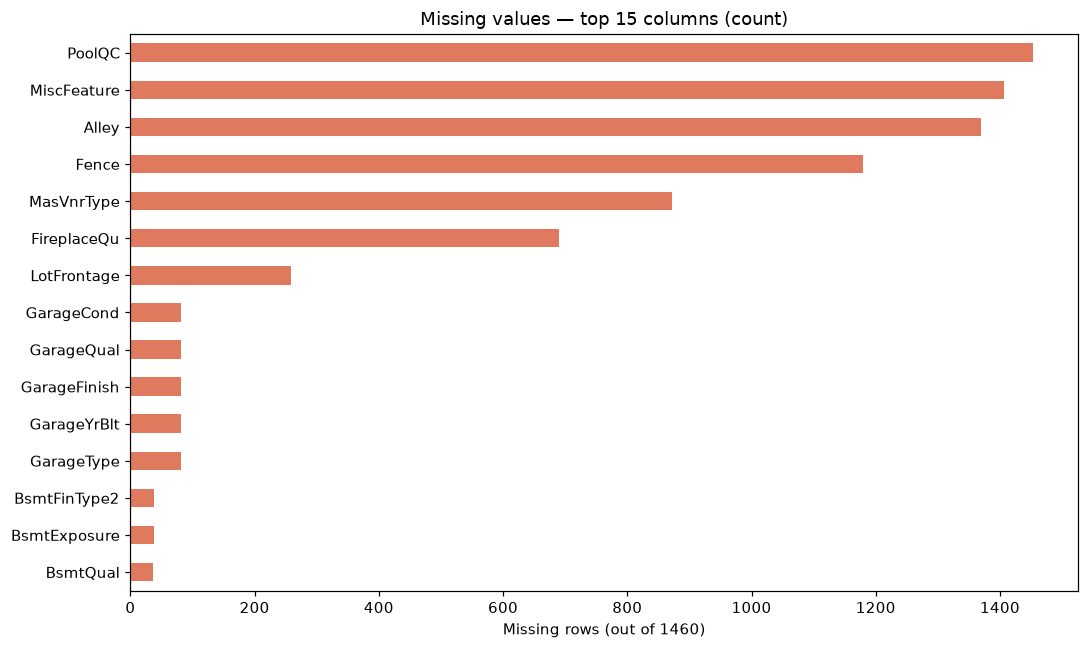

In [4]:
miss = df.isna().sum()
miss = miss[miss > 0].sort_values(ascending=False)
print(miss)
print("Total missing cells:", int(df.isna().sum().sum()))

fig, ax = plt.subplots(figsize=(10, 6))
miss.head(15).sort_values().plot(kind="barh", ax=ax, color="#E07A5F")
ax.set_title("Missing values — top 15 columns (count)")
ax.set_xlabel("Missing rows (out of 1460)")
fig.tight_layout()
fig.savefig("../figures/fig_missing.png")
plt.show()

## 4. Correlation — kaunsi cheez keemat badhati hai

**Kyun?** Correlation batata hai kaunsa feature target ke saath chalta hai. Isse do kaam hote hain: (1) sabse important features pehchan lo, (2) aage model ke result ko samajhna aasan ho jata hai.

**Observation:** `OverallQual` (0.79) sabse strong hai — ghar ki overall quality keemat ki sabse badi driver hai. Phir `GrLivArea` (0.71), `GarageCars` (0.64), `TotalBsmtSF` (0.61). Ye sab "ghar kitna bada/achha hai" wali baatein hain — logical hai.

OverallQual     0.791
GrLivArea       0.709
GarageCars      0.640
GarageArea      0.623
TotalBsmtSF     0.614
1stFlrSF        0.606
FullBath        0.561
TotRmsAbvGrd    0.534
YearBuilt       0.523
YearRemodAdd    0.507
GarageYrBlt     0.486
MasVnrArea      0.477
Name: SalePrice, dtype: float64


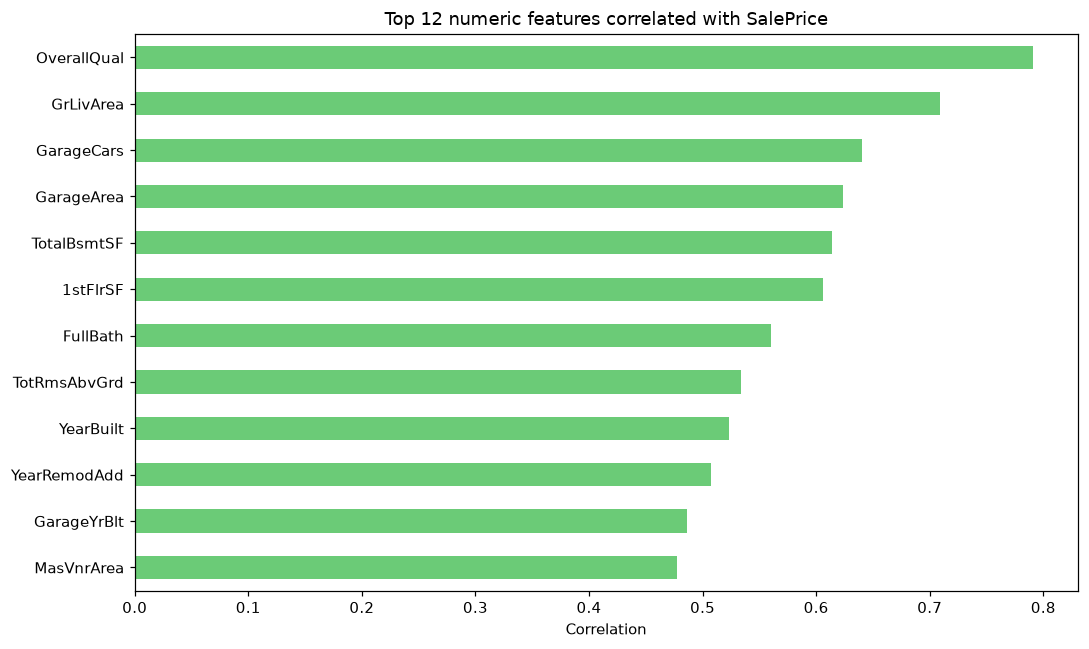

In [5]:
num = df.select_dtypes("number")
corr = num.corr(numeric_only=True)["SalePrice"].drop("SalePrice").sort_values(key=abs, ascending=False)
print(corr.head(12).round(3))

fig, ax = plt.subplots(figsize=(10, 6))
corr.head(12).sort_values().plot(kind="barh", ax=ax, color="#6BCB77")
ax.set_title("Top 12 numeric features correlated with SalePrice")
ax.set_xlabel("Correlation")
fig.tight_layout()
fig.savefig("../figures/fig_corr.png")
plt.show()

## 5. Categorical features — Neighborhood aur Quality

**Kyun?** Keemat sirf size se nahi banti — **location** bhi matter karta hai. 25 neighborhoods hain, aur median price me bada farak hai: NridgHt ~$315,000 vs sabse saste area ka ~$130,000. Isi liye Neighborhood ko model me lena zaroori hai.

`OverallQual` (1–10 rating) ke boxplot me saaf dikh raha hai: quality badhte hi keemat seedhi chadhti hai — ye linear regression ke liye achha sign hai.

Neighborhood
NridgHt    315000.0
NoRidge    301500.0
StoneBr    278000.0
Timber     228475.0
Somerst    225500.0
Name: SalePrice, dtype: float64


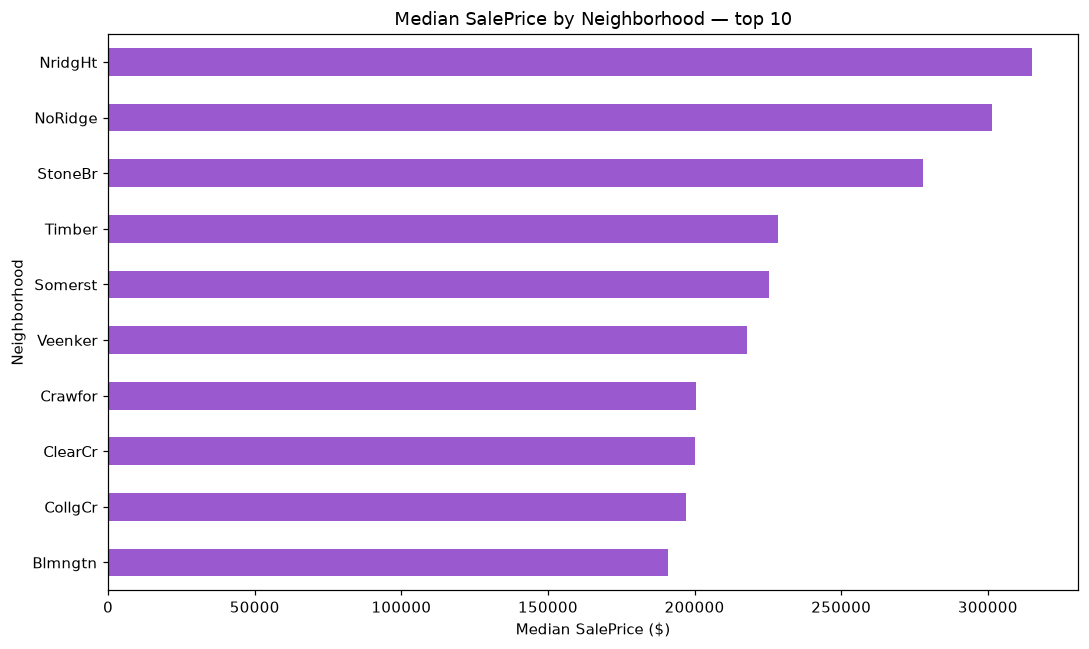

In [6]:
nb = df.groupby("Neighborhood")["SalePrice"].median().sort_values(ascending=False)
print(nb.head(5).round(0))

fig, ax = plt.subplots(figsize=(10, 6))
nb.head(10).sort_values().plot(kind="barh", ax=ax, color="#9B59D0")
ax.set_title("Median SalePrice by Neighborhood — top 10")
ax.set_xlabel("Median SalePrice ($)")
fig.tight_layout()
fig.savefig("../figures/fig_neighborhood.png")
plt.show()

## 6. Outliers — 2 ajeeb ghar

**Kyun dekhte hain?** Linear Regression ek line fit karta hai — 1–2 bahut ajeeb points poori line ko khinch lete hain.

**Observation:** Id **1299** (GrLivArea 5642 sq ft, price sirf $160,000) aur Id **524** (4676 sq ft, $184,750) — itne bade aur Quality-10 ghar itne saste nahi ho sakte. Ye partial sale / data entry issue lagte hain (Kaggle par bhi ye famous outliers hain). Inhe hatana sahi hai — inke bina model baaki 1458 gharon ko behtar seekhega.

        Id  GrLivArea  SalePrice  OverallQual
1298  1299       5642     160000           10
523    524       4676     184750           10
1182  1183       4476     745000           10
691    692       4316     755000           10


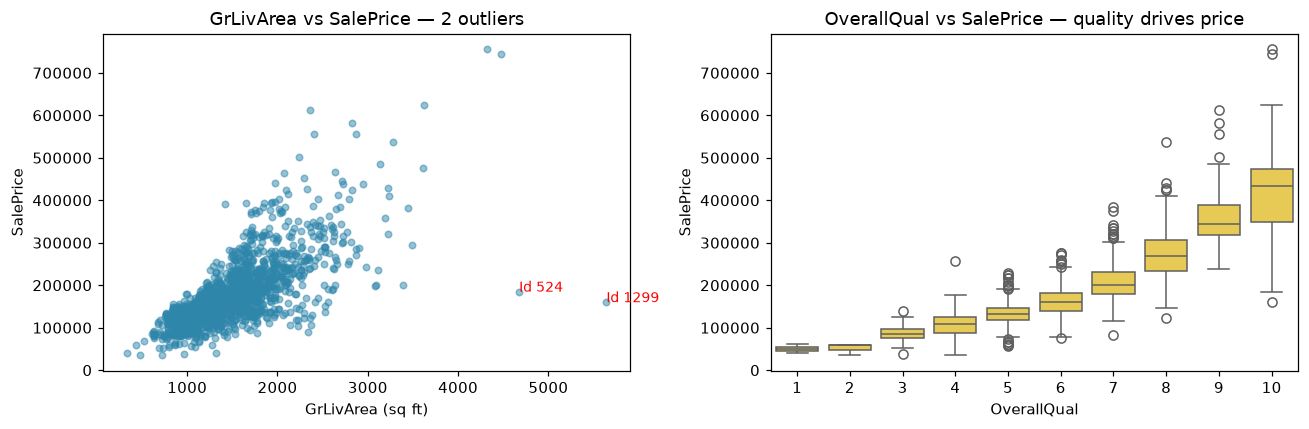

In [7]:
print(df.nlargest(4, "GrLivArea")[["Id", "GrLivArea", "SalePrice", "OverallQual"]])

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].scatter(df["GrLivArea"], df["SalePrice"], alpha=0.5, s=18, color="#2E86AB")
for _id in (1299, 524):
    r = df[df["Id"] == _id].iloc[0]
    ax[0].annotate(f"Id {_id}", (r["GrLivArea"], r["SalePrice"]), fontsize=9, color="red")
ax[0].set_xlabel("GrLivArea (sq ft)"); ax[0].set_ylabel("SalePrice")
ax[0].set_title("GrLivArea vs SalePrice — 2 outliers")
sns.boxplot(data=df, x="OverallQual", y="SalePrice", ax=ax[1], color="#FFD93D")
ax[1].set_title("OverallQual vs SalePrice — quality drives price")
fig.tight_layout()
fig.savefig("../figures/fig_scatter.png")
plt.show()

## 7. FEATURE ENGINEERING — MINDSET (ye section sabse important hai)

Feature Engineering ka matlab sirf "columns banana" nahi hai — **sochne ka tareeka** hai. Har step se pehle ye 7 sawal poochho:

| # | Sawal | Matlab |
|---|-------|--------|
| 1 | **Ye column kya kehta hai?** | Pehle feature ka real-world matlab samjho (GrLivArea = upar wale floors ka area). |
| 2 | **Problem KYUN hai?** | Missing/skew/outlier hai to pehle wajah samjho — wajah hi solution batati hai. |
| 3 | **Model ko kya nayi info milegi?** | Har naya feature ek nayi information hona chahiye, purani cheez ka repeat nahi. |
| 4 | **Ye info test time par milegi?** | Agar feature banane me target (SalePrice) use ho gaya, to wo **leakage** hai — model exam me fail hoga. |
| 5 | **Simple tareeka kya hai?** | Pehle simple solution try karo (median, group median) — complex tabhi jab simple fail ho. |
| 6 | **Order hai ya nahi?** | Quality (Ex < Gd < TA...) me order hai → number do. Neighborhood me order nahi → one-hot karo. |
| 7 | **Scale matter karta hai?** | Linear Regression me bade numbers (LotArea ~10,000) chhote numbers (FullBath ~2) ko daba dete hain → scaling zaroori (agle step me). |

**FE ka flow (hamesha yahi order):**
`Target samjho → Data dekho → Problem pehchano → Wajah socho → Domain knowledge lagao → Step karo → Verify karo`

Neeche har step me **"Soch"** likhi hai — wahi soch jo step karne se pehle dimaag me chali thi.

## 8. FE Step 1 — Outliers hatana

**Soch:** GrLivArea 4600+ lekin price 1.6–1.8 lakh — ye combination real life me possible nahi. 2 points ke liye 1458 points ka model kharab karna bewakoofi hai. **Rule:** outlier tabhi hatao jab tum wajah bata sako — "bas bada hai" wajah nahi hoti.

In [8]:
fe = df.copy()
fe = fe[~fe["Id"].isin([1299, 524])].copy()
print("Rows after dropping outliers:", fe.shape[0], "(2 dropped)")

Rows after dropping outliers: 1458 (2 dropped)


## 9. FE Step 2 — Missing values bharna (3 groups, 3 alag soch)

**Group A — "None" bharo** (PoolQC, MiscFeature, Alley, Fence, FireplaceQu, Garage*, Bsmt*, MasVnrType):
**Soch:** missing matlab cheez hai hi nahi. "None" ek category hai, kami nahi — model khud seekhega ki "pool nahi hai" ka price par kya asar hai.

**Group B — LotFrontage: Neighborhood-wise median:**
**Soch:** ek hi area ke gharon ki frontage aas-paas hoti hai. Poore dataset ka median bharna galat hota — ameer area ki frontage badi hoti hai, gareeb area ki chhoti. Group median zyada sahi estimate hai.

**Group C — chhoti missing:** MasVnrArea (8 rows) → 0 jab MasVnrType "None" hai, warna median. Electrical (1 row) → mode. GarageYrBlt (81 rows, garage nahi hai) → median.

In [9]:
none_cols = ["PoolQC", "MiscFeature", "Alley", "Fence", "FireplaceQu",
             "GarageType", "GarageFinish", "GarageQual", "GarageCond",
             "BsmtQual", "BsmtCond", "BsmtExposure", "BsmtFinType1", "BsmtFinType2",
             "MasVnrType"]
for c in none_cols:
    fe[c] = fe[c].fillna("None")

fe["LotFrontage"] = fe.groupby("Neighborhood")["LotFrontage"].transform(
    lambda s: s.fillna(s.median()))

fe.loc[fe["MasVnrType"] == "None", "MasVnrArea"] = fe.loc[
    fe["MasVnrType"] == "None", "MasVnrArea"].fillna(0)
fe["MasVnrArea"] = fe["MasVnrArea"].fillna(fe["MasVnrArea"].median())
fe["Electrical"] = fe["Electrical"].fillna(fe["Electrical"].mode()[0])
fe["GarageYrBlt"] = fe["GarageYrBlt"].fillna(fe["GarageYrBlt"].median())
print("Remaining missing values:", int(fe.isna().sum().sum()))

Remaining missing values: 0


## 10. FE Step 3 — Naye features banana (domain knowledge)

**Soch:** Kharidne wala alag-alag tukde nahi sochta — wo sochta hai *"kul kitna area, kul kitne bathroom, ghar kitna purana"*. Model ko bhi wahi number do:
- **TotalSF** = basement + ground floor + first floor (kul rehne ka area)
- **TotalBath** = full bath + 0.5×half bath (upar + basement) — half bath aadha gina jata hai
- **TotalPorchSF** = saare porch milakar
- **HouseAge** = YrSold − YearBuilt, **RemodAge** = YrSold − YearRemodAdd (saal likhne se behtar hai "umar" likhna)
- **HasPool / HasGarage / HasFireplace / HasBsmt** — 0/1 flags (hai ya nahi)

In [10]:
fe["TotalSF"] = fe["TotalBsmtSF"] + fe["1stFlrSF"] + fe["2ndFlrSF"]
fe["TotalBath"] = (fe["FullBath"] + 0.5 * fe["HalfBath"]
                   + fe["BsmtFullBath"] + 0.5 * fe["BsmtHalfBath"])
fe["TotalPorchSF"] = (fe["OpenPorchSF"] + fe["EnclosedPorch"]
                      + fe["3SsnPorch"] + fe["ScreenPorch"])
fe["HouseAge"] = fe["YrSold"] - fe["YearBuilt"]
fe["RemodAge"] = fe["YrSold"] - fe["YearRemodAdd"]
fe["HasPool"] = (fe["PoolArea"] > 0).astype(int)
fe["HasGarage"] = (fe["GarageArea"] > 0).astype(int)
fe["HasFireplace"] = (fe["Fireplaces"] > 0).astype(int)
fe["HasBsmt"] = (fe["TotalBsmtSF"] > 0).astype(int)

print("New features vs SalePrice correlation:")
print(fe[["TotalSF", "TotalBath", "HouseAge", "TotalPorchSF"]]
      .corrwith(fe["SalePrice"]).round(3))

New features vs SalePrice correlation:
TotalSF         0.833
TotalBath       0.636
HouseAge       -0.524
TotalPorchSF    0.197
dtype: float64


## 11. FE Step 4 — Ordinal encoding (order wali categories)

**Soch:** `ExterQual` me Ex > Gd > TA > Fa > Po ek **order** hai. Agar one-hot kar doge, to ye order kho jayega aur model ko ye nahi pata chalega ki "Gd, TA se behtar hai". Isliye order wali categories ko number do: None=0, Po=1, Fa=2, TA=3, Gd=4, Ex=5. (BsmtFinType, Functional, Fence, LotShape ka bhi apna order hai — same logic.)

In [11]:
ordinal_map = {"None": 0, "Po": 1, "Fa": 2, "TA": 3, "Gd": 4, "Ex": 5}
ord_cols = ["ExterQual", "ExterCond", "BsmtQual", "BsmtCond", "HeatingQC",
            "KitchenQual", "FireplaceQu", "GarageQual", "GarageCond", "PoolQC"]
for c in ord_cols:
    fe[c] = fe[c].map(ordinal_map)
fe["BsmtExposure"] = fe["BsmtExposure"].map({"None": 0, "No": 1, "Mn": 2, "Av": 3, "Gd": 4})
fe["BsmtFinType1"] = fe["BsmtFinType1"].map({"None": 0, "Unf": 1, "LwQ": 2, "Rec": 3, "BLQ": 4, "ALQ": 5, "GLQ": 6})
fe["BsmtFinType2"] = fe["BsmtFinType2"].map({"None": 0, "Unf": 1, "LwQ": 2, "Rec": 3, "BLQ": 4, "ALQ": 5, "GLQ": 6})
fe["Functional"] = fe["Functional"].map({"Sal": 0, "Sev": 1, "Maj2": 2, "Maj1": 3, "Mod": 4, "Min2": 5, "Min1": 6, "Typ": 7})
fe["Fence"] = fe["Fence"].map({"None": 0, "MnWw": 1, "GdWo": 2, "MnPrv": 3, "GdPrv": 4})
fe["LotShape"] = fe["LotShape"].map({"IR3": 0, "IR2": 1, "IR1": 2, "Reg": 3})
print("Ordinal encoding done. Example — ExterQual values:", sorted(fe["ExterQual"].unique()))

Ordinal encoding done. Example — ExterQual values: [np.int64(2), np.int64(3), np.int64(4), np.int64(5)]


## 12. FE Step 5 — Skew theek karna (log1p)

**Soch:** Linear Regression assume karta hai ki residuals normal honge. Right-skewed features (LotArea skew 12.21, GrLivArea 1.37) is assumption ko todte hain — kuch bahut bade values poori line ko khinch lete hain. `log1p` skew ko dabata hai, aur 0 wale values bhi safe rehte hain (log(0) error nahi deta, log1p(0) = 0 hota hai).

In [12]:
skewed = ["LotFrontage", "LotArea", "MasVnrArea", "BsmtFinSF1", "BsmtFinSF2",
          "BsmtUnfSF", "TotalBsmtSF", "1stFlrSF", "2ndFlrSF", "GrLivArea",
          "WoodDeckSF", "OpenPorchSF", "EnclosedPorch", "3SsnPorch",
          "ScreenPorch", "MiscVal", "PoolArea", "LowQualFinSF", "TotalSF"]
for c in skewed:
    fe[c] = np.log1p(fe[c])
fe["SalePrice_log"] = np.log1p(fe["SalePrice"])
print("GrLivArea skew before: 1.37 → after log1p:", round(fe["GrLivArea"].skew(), 2))
print("SalePrice skew before: 1.88 → after log1p:", round(fe["SalePrice_log"].skew(), 2))

GrLivArea skew before: 1.37 → after log1p: -0.07
SalePrice skew before: 1.88 → after log1p: 0.12


## 13. FE Step 6 — One-hot encoding (bina order wali categories)

**Soch:** Neighborhood, MSZoning me koi order nahi hai — NridgHt ko "25" aur OldTown ko "1" likhna bekaar hai, model samjhega ki 25 > 1 matlab behtar hai, jo galat hai. Isliye inhe 0/1 columns me todo. `drop_first=True` isliye — taaki columns aapas me duplicate info na dein (multicollinearity se bachna).

In [13]:
nom_cols = fe.select_dtypes(include="object").columns.tolist()
print("One-hot karne wale columns:", len(nom_cols))
fe = pd.get_dummies(fe, columns=nom_cols, drop_first=True, dtype=int)
fe = fe.drop(columns=["Id"])
print("Final shape:", fe.shape)
print("Remaining missing:", int(fe.isna().sum().sum()))

One-hot karne wale columns: 27
Final shape: (1458, 216)
Remaining missing: 0


## 14. Final check + save

**Verify karo (ye step kabhi mat chhodo):** shape sahi hai? Missing zero hai? Naye features bane? Agar koi step galat hota, to yahin pakda jata.

In [14]:
fe.to_csv("../data/train_engineered.csv", index=False)
print("Saved: data/train_engineered.csv")
print("Shape: 1460 rows →", fe.shape[0], "rows (2 outliers gaye),",
      "81 columns →", fe.shape[1], "columns (one-hot se badhe)")
print("Missing values:", int(fe.isna().sum().sum()))
fe[["TotalSF", "TotalBath", "HouseAge", "SalePrice", "SalePrice_log"]].head()

Saved: data/train_engineered.csv
Shape: 1460 rows → 1458 rows (2 outliers gaye), 81 columns → 216 columns (one-hot se badhe)
Missing values: 0


,TotalSF,TotalBath,HouseAge,SalePrice,SalePrice_log
0,7.850493,3.5,5,208500,12.247699
1,7.833996,2.5,31,181500,12.109016
2,7.903596,3.5,7,223500,12.317171
3,7.813592,2.0,91,140000,11.849405
4,8.114923,3.5,8,250000,12.429220


## Aage kya? (Next steps — tum batoge)

1. **Train/test split** — data ko 80/20 me baanto.
2. **Scaling (StandardScaler)** — sirf **train par fit** karke test par apply karna. Poore data par fit karna **leakage** hota hai (test ki info train me aa jati hai).
3. **Linear Regression** (1 feature, jaise GrLivArea) → phir **Multiple Linear Regression** (saare features).
4. **Evaluation:** R², RMSE, MAE — aur residuals plot se check karna ki model kahan galat hai.
5. **Multicollinearity check:** GarageCars vs GarageArea (r = 0.88) — dono ek hi baat kehte hain, ek ko hatana ya combine karna pad sakta hai.

**Yaad rakhne wali baat:** Feature Engineering koi recipe nahi hai — ye **sochne ka tareeka** hai. Har dataset par yahi 7 sawal poochho, aur steps khud samajh aane lagenge.